# Infographix — DBSCAN Layout Clustering, COCO Schema & Aim Benchmarking

**Purpose:** Evaluate density-based clustering (DBSCAN + PCA) on scientific poster layouts, demonstrate the unified COCO data schema, test micro-level 2D spatial block grouping, and compare performance against the K-Means baseline while tracking runs in Aim.

**Inputs:** `data/processed/features/*_features.parquet`
**Outputs:** Benchmark reports in `reports/comparisons/`, Aim tracking logs, and layout clusters.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.clustering.dbscan_clustering import PosterLayoutDBSCAN, SpatialBlockDBSCAN
from src.schemas.coco import convert_canvas_to_coco, convert_extracted_document_to_coco, validate_coco_structure
from src.tracking.tracker import ExperimentTracker

print("Project root:", PROJECT_ROOT)

Project root: /home/rahul/Projects/infographix


## 1. Load Preprocessed Layout Features
We load the engineered features created by `02_feature_engineering.ipynb`.

In [2]:
from src.clustering.comparison import load_and_preprocess_data

(X_train, X_dev, X_test), feature_cols = load_and_preprocess_data()
print(f"Train: {X_train.shape}, Dev: {X_dev.shape}, Test: {X_test.shape}")
print(f"Number of layout features: {len(feature_cols)}")

Train: (6855, 92), Dev: (500, 92), Test: (500, 92)
Number of layout features: 92


## 2. PCA Dimensionality Reduction & K-Distance Elbow Plot
In high-dimensional space (92 features), points become equidistant. We reduce to 15 components and plot the k-nearest-neighbour distance curve to find the optimal epsilon.

Explained variance with 15 components: 62.68%


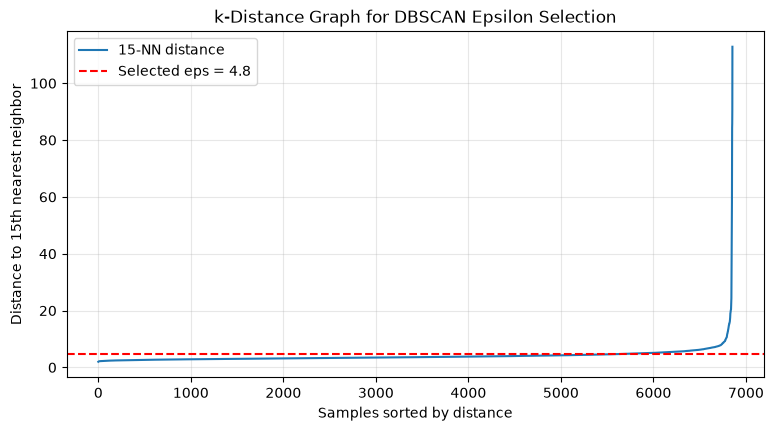

In [3]:
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

pca = PCA(n_components=15, random_state=42)
X_train_pca = pca.fit_transform(X_train)
explained_var = np.sum(pca.explained_variance_ratio_)
print(f"Explained variance with 15 components: {explained_var * 100:.2f}%")

# k-distance elbow curve (with k = min_samples = 15)
k = 15
nn = NearestNeighbors(n_neighbors=k).fit(X_train_pca)
distances, _ = nn.kneighbors(X_train_pca)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4.5))
plt.plot(k_distances, label="15-NN distance")
plt.axhline(4.8, color="r", linestyle="--", label="Selected eps = 4.8")
plt.title("k-Distance Graph for DBSCAN Epsilon Selection")
plt.xlabel("Samples sorted by distance")
plt.ylabel("Distance to 15th nearest neighbor")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Fit PosterLayoutDBSCAN and Evaluate Partitions
We fit on `train` and evaluate out-of-sample on `dev` and `test`.

In [4]:
model = PosterLayoutDBSCAN(pca_components=15, eps=4.8, min_samples=15)
train_labels = model.fit_predict(X_train)

train_eval = model.evaluate_clusters(X_train, train_labels)
dev_labels = model.predict(X_dev)
dev_eval = model.evaluate_clusters(X_dev, dev_labels)
test_labels = model.predict(X_test)
test_eval = model.evaluate_clusters(X_test, test_labels)

summary_df = pd.DataFrame([
    {"Split": "Train", **train_eval},
    {"Split": "Dev", **dev_eval},
    {"Split": "Test", **test_eval},
])
display(summary_df[["Split", "clusters_present", "noise_count", "noise_ratio", "silhouette_clean", "davies_bouldin"]])

,Split,clusters_present,noise_count,noise_ratio,silhouette_clean,davies_bouldin
0,Train,2,424,0.061853,0.247516,1.211590
1,Dev,2,28,0.056000,0.196320,0.684513
2,Test,2,24,0.048000,0.246863,1.025020


## 4. COCO Schema Demonstration
Demonstrates converting extracted research document elements and visual canvas states into standard COCO format.

In [5]:
sections = [
    {"category_name": "title", "bbox": [100.0, 50.0, 1720.0, 120.0], "text_content": "AI in Healthcare"},
    {"category_name": "author_info", "bbox": [100.0, 180.0, 1720.0, 50.0], "text_content": "Jane Doe et al."},
    {"category_name": "abstract", "bbox": [100.0, 250.0, 500.0, 300.0], "text_content": "Summary..."},
    {"category_name": "figure", "bbox": [650.0, 250.0, 600.0, 400.0]},
    {"category_name": "caption", "bbox": [650.0, 660.0, 600.0, 40.0], "text_content": "Fig 1: Pipeline"},
]
coco_dataset = convert_extracted_document_to_coco(doc_id="poster_001", extracted_sections=sections)
is_valid, msg = validate_coco_structure(coco_dataset.to_dict())
print(f"COCO Schema Validation: {is_valid} ({msg})")
print("COCO Annotations count:", len(coco_dataset.annotations))

COCO Schema Validation: True (Valid COCO structure)
COCO Annotations count: 5


## 5. Micro-Level 2D Spatial DBSCAN (Column & Caption Grouping)

In [6]:
grouper = SpatialBlockDBSCAN(horizontal_weight=1.0, vertical_weight=0.5, eps=60.0)
raw_text_boxes = [
    [100.0, 250.0, 450.0, 30.0],
    [100.0, 290.0, 450.0, 30.0],
    [100.0, 330.0, 450.0, 30.0],
    [650.0, 250.0, 450.0, 30.0],
    [650.0, 290.0, 450.0, 30.0],
]
box_clusters = grouper.cluster_boxes(raw_text_boxes)
print("Column / Section Clusters for text boxes:", box_clusters)

Column / Section Clusters for text boxes: [0 0 0 1 1]
